# Inspeccionem les imatges i veiem si les dades estan bé i els seus atributs també

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

### Introduim les dades i revisem el json 



In [11]:
data_dir = Path("data/raw/dentex")

images_dir = (
    data_dir
    / "validation_data"
    / "quadrant_enumeration_disease"
    / "xrays"
)

json_path = data_dir / "validation_triple.json"

with open(json_path, "r") as f:
    data = json.load(f)



print(f"Imatges: {len(data['images'])}")
print(f"Anotacions: {len(data['annotations'])}")
print(data.keys())

Imatges: 50
Anotacions: 182
dict_keys(['images', 'annotations', 'categories_1', 'categories_2', 'categories_3'])


## Fem els diccionaris que tradueixen les categories

In [8]:
quadrants = {x["id"]: x["name"] for x in data["categories_1"]}
teeth = {x["id"]: x["name"] for x in data["categories_2"]}
diagnoses = {x["id"]: x["name"] for x in data["categories_3"]}

print(diagnoses)

{0: 'Impacted', 1: 'Caries', 2: 'Periapical Lesion', 3: 'Deep Caries'}


## Probem a tirar una foto i localitzar la info

que fa el next?

In [9]:
file_name = "val_15.png"

# Troba les metadades d'aquesta imatge
image_info = next(img for img in data["images"] if img["file_name"] == file_name)
image_id = image_info["id"]

# Troba totes les dents anòmales d'aquesta imatge
annotations = [
    ann for ann in data["annotations"]
    if ann["image_id"] == image_id
]

print(f"Imatge: {file_name}")
print(f"Mida anotada: {image_info['width']} x {image_info['height']}")
print(f"Troballes: {len(annotations)}")

Imatge: val_15.png
Mida anotada: 2892 x 1316
Troballes: 7


### Ara intentem pintar la imatge amb les coses

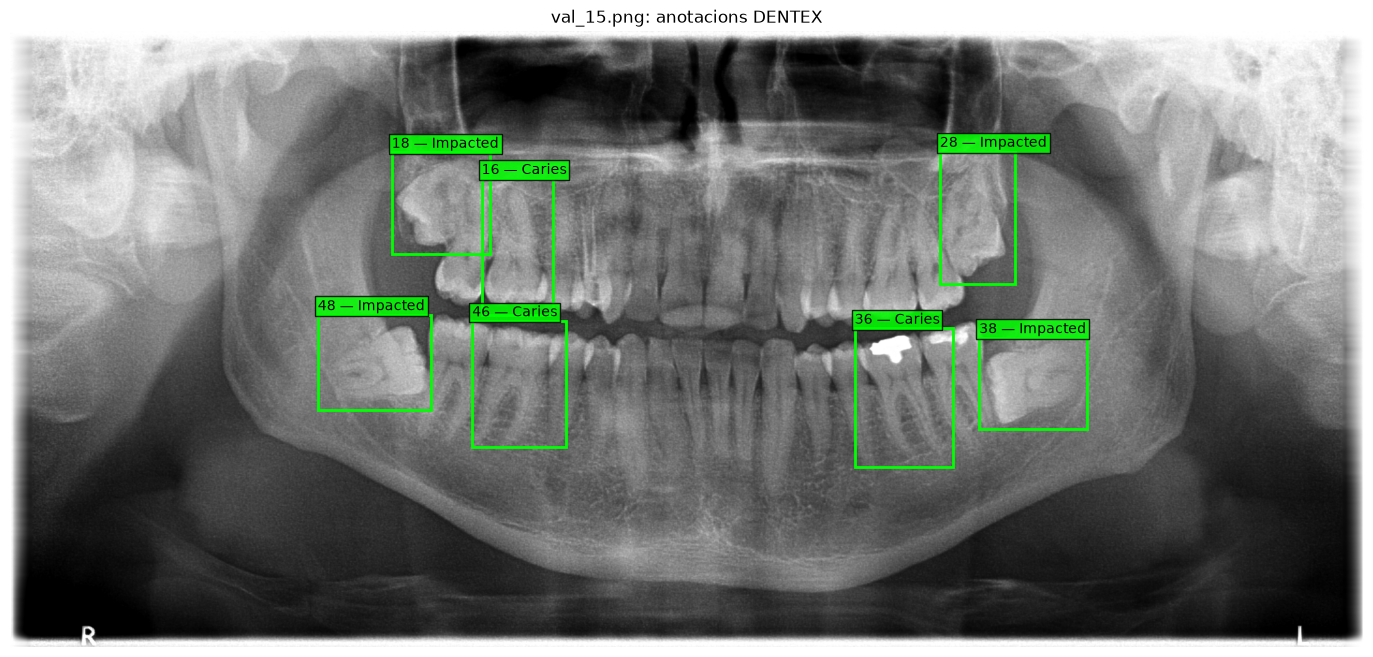

In [10]:
image = Image.open(images_dir / file_name)

fig, ax = plt.subplots(figsize=(18, 8))
ax.imshow(image, cmap="gray")

for ann in annotations:
    x, y, width, height = ann["bbox"]

    # Dibuixa el rectangle
    box = Rectangle(
        (x, y),
        width,
        height,
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )
    ax.add_patch(box)

    # Construeix l'etiqueta, per exemple: "48 — Impacted"
    fdi = quadrants[ann["category_id_1"]] + teeth[ann["category_id_2"]]
    diagnosis = diagnoses[ann["category_id_3"]]
    label = f"{fdi} — {diagnosis}"

    ax.text(
        x,
        y - 10,
        label,
        color="black",
        fontsize=10,
        bbox={"facecolor": "lime", "alpha": 0.85, "pad": 2}
    )

ax.set_title(f"{file_name}: anotacions DENTEX")
ax.axis("off")
plt.show()